27-Nov-2026 12:57:04 DEBUG utils - Directory . already exists. Skipping.
DEBUG:GEOparse:Directory . already exists. Skipping.
27-Nov-2026 12:57:04 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/soft/GSE10072_family.soft.gz to ./GSE10072_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/soft/GSE10072_family.soft.gz to ./GSE10072_family.soft.gz


100%|██████████| 25.6M/25.6M [00:04<00:00, 6.46MB/s]
27-Nov-2026 12:57:10 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
27-Nov-2026 12:57:10 DEBUG downloader - Moving /tmp/tmp43gookai to /content/GSE10072_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp43gookai to /content/GSE10072_family.soft.gz
27-Nov-2026 12:57:10 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/soft/GSE10072_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/soft/GSE10072_family.soft.gz
27-Nov-2026 12:57:10 INFO GEOparse - Parsing ./GSE10072_family.soft.gz: 
INFO:GEOparse:Parsing ./GSE10072_family.soft.gz: 
27-Nov-2026 12:57:10 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
27-Nov-2026 12:57:10 DEBUG GEOparse - SERIES: GSE10072
DEBUG:GEOparse:SERIES: GSE10072
27-Nov-2026 12:57:10 DEBUG GEOparse - PLATFORM: GPL96
DEBUG:GEOparse:PLATFORM: GPL96
27-Nov-2026 

Dataset downloaded successfully!
Expression Matrix Shape: (22283, 107)

Sample Distribution:
Group
Tumor    107
Name: count, dtype: int64

Cleaned Dataset Shape: (22283, 107)


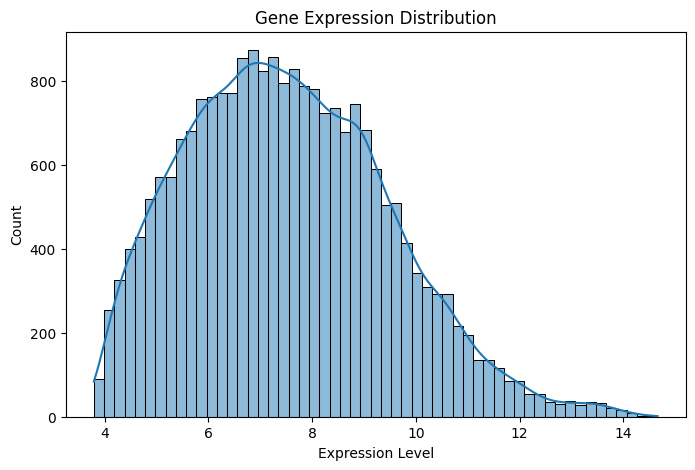

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)



Top Differentially Expressed Genes:
        Gene  Tumor_Mean  Normal_Mean  Log2FC  P_Value  Adjusted_P_Value  \
0  1007_s_at   10.560596          NaN     NaN      NaN               NaN   
1    1053_at    6.872995          NaN     NaN      NaN               NaN   
2     117_at    8.012540          NaN     NaN      NaN               NaN   
3     121_at    9.871100          NaN     NaN      NaN               NaN   
4  1255_g_at    4.892962          NaN     NaN      NaN               NaN   
5    1294_at    8.939194          NaN     NaN      NaN               NaN   
6    1316_at    6.302487          NaN     NaN      NaN               NaN   
7    1320_at    6.159289          NaN     NaN      NaN               NaN   
8  1405_i_at    8.245530          NaN     NaN      NaN               NaN   
9    1431_at    4.956845          NaN     NaN      NaN               NaN   

        Regulation  
0  Not Significant  
1  Not Significant  
2  Not Significant  
3  Not Significant  
4  Not Significant  


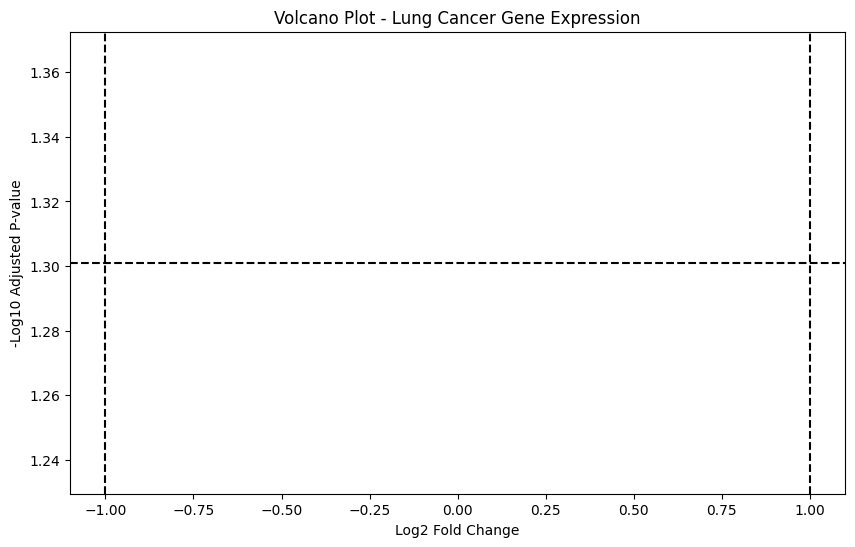

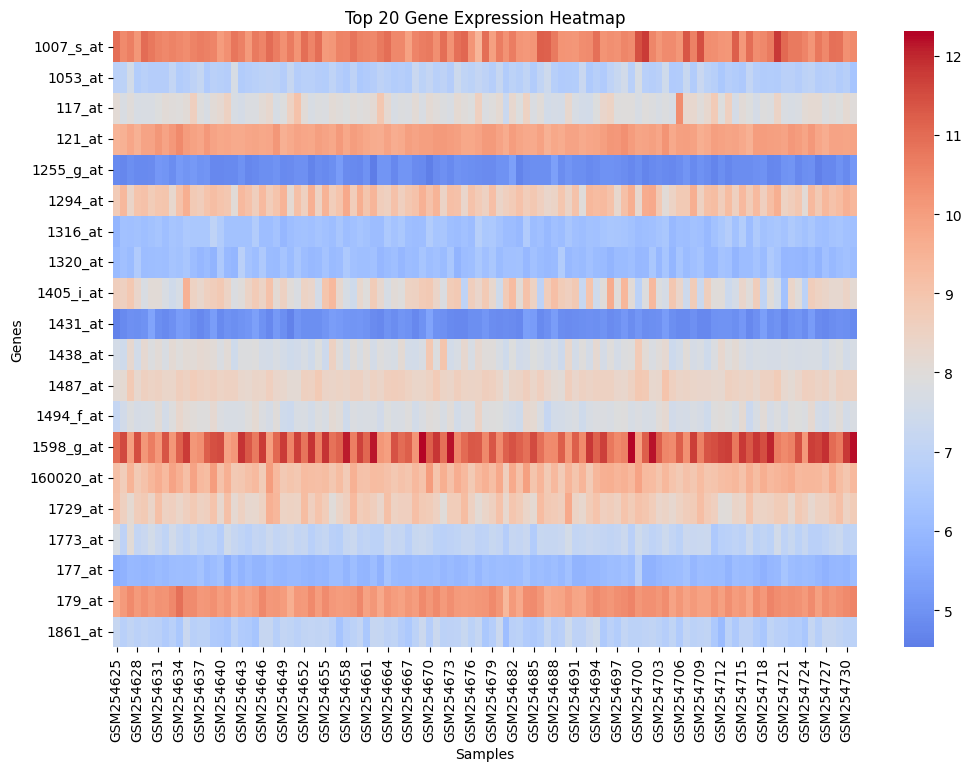

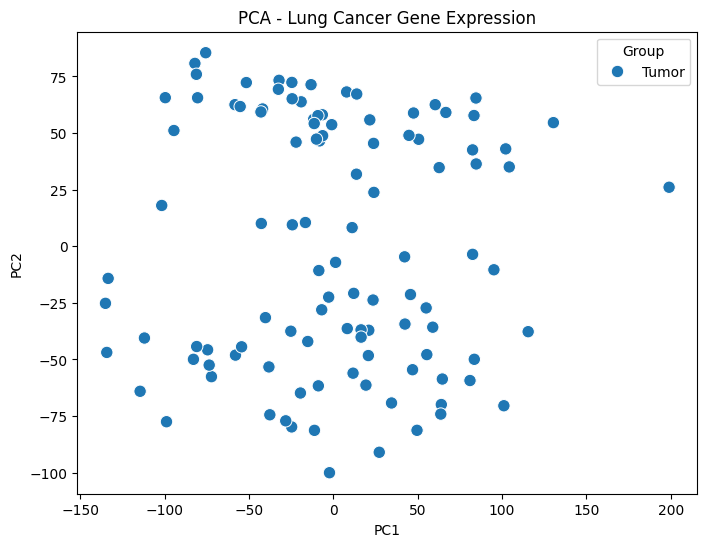


Analysis Completed Successfully!
Results saved as CSV files.


In [7]:

# ============================================================
# GENE EXPRESSION ANALYSIS FOR LUNG CANCER
# ============================================================

# 1. IMPORT LIBRARIES

!pip install GEOparse seaborn statsmodels -q

import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ============================================================
# 2. DOWNLOAD LUNG CANCER DATASET
# ============================================================

print("Downloading Lung Cancer Gene Expression Dataset...")

gse = GEOparse.get_GEO(
    "GSE10072",
    destdir="."
)

expression_data = gse.pivot_samples("VALUE")

print("Dataset downloaded successfully!")

print("Expression Matrix Shape:", expression_data.shape)

# ============================================================
# 3. EXTRACT SAMPLE INFORMATION
# ============================================================

metadata = []

for gsm_name, gsm in gse.gsms.items():

    characteristics = gsm.metadata.get(
        "characteristics_ch1", []
    )

    metadata.append({
        "Sample": gsm_name,
        "Characteristics": " ".join(characteristics)
    })

metadata = pd.DataFrame(metadata)

# Identify tumor and normal samples
metadata["Group"] = metadata["Characteristics"].apply(
    lambda x: "Normal" if "normal" in x.lower() else "Tumor"
)

metadata = metadata.set_index("Sample")

# Match expression columns with metadata
common_samples = expression_data.columns.intersection(
    metadata.index
)

expression_data = expression_data[common_samples]

metadata = metadata.loc[common_samples]

print("\nSample Distribution:")
print(metadata["Group"].value_counts())

# ============================================================
# 4. DATA PREPROCESSING
# ============================================================

# Convert expression values to numeric
expression_data = expression_data.apply(
    pd.to_numeric,
    errors="coerce"
)

# Remove missing values
expression_data = expression_data.dropna()

# Remove duplicate gene identifiers
expression_data = expression_data[
    ~expression_data.index.duplicated(keep="first")
]

print("\nCleaned Dataset Shape:", expression_data.shape)

# ============================================================
# 5. EXPLORATORY DATA ANALYSIS
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    expression_data.iloc[:, 0],
    kde=True
)

plt.title("Gene Expression Distribution")
plt.xlabel("Expression Level")
plt.show()

# ============================================================
# 6. DIFFERENTIAL GENE EXPRESSION ANALYSIS
# ============================================================

tumor_samples = metadata[
    metadata["Group"] == "Tumor"
].index

normal_samples = metadata[
    metadata["Group"] == "Normal"
].index

tumor_data = expression_data[tumor_samples]

normal_data = expression_data[normal_samples]

results = []

for gene in expression_data.index:

    tumor_values = tumor_data.loc[gene].values
    normal_values = normal_data.loc[gene].values

    # Calculate average expression
    tumor_mean = np.mean(tumor_values)
    normal_mean = np.mean(normal_values)

    # Calculate log2 fold change
    log2fc = tumor_mean - normal_mean

    # Statistical significance
    _, p_value = ttest_ind(
        tumor_values,
        normal_values,
        equal_var=False
    )

    results.append([
        gene,
        tumor_mean,
        normal_mean,
        log2fc,
        p_value
    ])

deg_results = pd.DataFrame(
    results,
    columns=[
        "Gene",
        "Tumor_Mean",
        "Normal_Mean",
        "Log2FC",
        "P_Value"
    ]
)

# ============================================================
# 7. MULTIPLE TESTING CORRECTION
# ============================================================

deg_results["Adjusted_P_Value"] = multipletests(
    deg_results["P_Value"],
    method="fdr_bh"
)[1]

deg_results["Regulation"] = "Not Significant"

deg_results.loc[
    (deg_results["Adjusted_P_Value"] < 0.05) &
    (deg_results["Log2FC"] > 1),
    "Regulation"
] = "Upregulated"

deg_results.loc[
    (deg_results["Adjusted_P_Value"] < 0.05) &
    (deg_results["Log2FC"] < -1),
    "Regulation"
] = "Downregulated"

# Sort results
deg_results = deg_results.sort_values(
    "Adjusted_P_Value"
)

print("\nTop Differentially Expressed Genes:")

print(deg_results.head(10))

# ============================================================
# 8. IDENTIFY SIGNIFICANT GENES
# ============================================================

significant_genes = deg_results[
    deg_results["Regulation"] != "Not Significant"
]

print("\nTotal Significant Genes:",
      len(significant_genes))

print("\nUpregulated Genes:",
      len(significant_genes[
          significant_genes["Regulation"] == "Upregulated"
      ]))

print("\nDownregulated Genes:",
      len(significant_genes[
          significant_genes["Regulation"] == "Downregulated"
      ]))

# ============================================================
# 9. VOLCANO PLOT
# ============================================================

plt.figure(figsize=(10, 6))

colors = deg_results["Regulation"].map({
    "Upregulated": "red",
    "Downregulated": "blue",
    "Not Significant": "gray"
})

plt.scatter(
    deg_results["Log2FC"],
    -np.log10(deg_results["Adjusted_P_Value"].clip(lower=1e-300)),
    c=colors,
    alpha=0.6
)

plt.axhline(-np.log10(0.05), linestyle="--", color="black")

plt.axvline(1, linestyle="--", color="black")

plt.axvline(-1, linestyle="--", color="black")

plt.title("Volcano Plot - Lung Cancer Gene Expression")

plt.xlabel("Log2 Fold Change")

plt.ylabel("-Log10 Adjusted P-value")

plt.show()

# ============================================================
# 10. HEATMAP OF TOP 20 GENES
# ============================================================

top_genes = deg_results.head(20)["Gene"]

heatmap_data = expression_data.loc[top_genes]

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm",
    center=heatmap_data.values.mean()
)

plt.title("Top 20 Gene Expression Heatmap")

plt.xlabel("Samples")

plt.ylabel("Genes")

plt.show()

# ============================================================
# 11. PRINCIPAL COMPONENT ANALYSIS (PCA)
# ============================================================

X = expression_data.T

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)

pca_result = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

pca_df["Group"] = metadata["Group"].values

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Group",
    s=80
)

plt.title("PCA - Lung Cancer Gene Expression")

plt.show()

# ============================================================
# 12. SAVE RESULTS
# ============================================================

deg_results.to_csv(
    "Lung_Cancer_Gene_Expression_Results.csv",
    index=False
)

significant_genes.to_csv(
    "Significant_Lung_Cancer_Genes.csv",
    index=False
)

print("\nAnalysis Completed Successfully!")

print("Results saved as CSV files.")
